In [1]:
import pandas as pd
from stress.scenarios import compare, PRESETS

In [16]:
feats = pd.read_csv(r"..\data\features.csv", parse_dates=["date"])
port  = pd.read_csv(r"..\data\portfolio.csv")

In [7]:
latest = feats.sort_values("date").groupby("ticker").tail(1)
print(latest.columns.tolist())   # check these names match the next lines

book = (port.merge(latest[["ticker", "close", "adv20", "vol20", "spread20"]], on="ticker")
            .rename(columns={"close": "price"}))

['date', 'ticker', 'close', 'volume', 'ret', 'hl_range', 'traded_value', 'adv20', 'adv_value20', 'volume_ratio', 'vol20', 'vol20_ann', 'amihud20', 'spread_raw', 'spread20', 'atr_pct', 'cs_clipped20', 'ret_20d', 'trend_50', 'drawdown252', 'volume_ratio_z', 'hl_range_z', 'vol20_z']


In [8]:
table, summary = compare(book, **PRESETS["Severe (PS preset)"])
summary

{'cost_normal': 505848253.44317967,
 'cost_stress': 850348092.6666471,
 'bps_normal': 73.78630067108868,
 'bps_stress': 124.0372772140763,
 'longest_exit_normal': 80,
 'longest_exit_stress': 160}

In [10]:
from stress.scenarios import monte_carlo
import matplotlib.pyplot as plt

In [11]:
total, mc = monte_carlo(book, runs=2000)

In [12]:
cr = 1e7
print("normal   :", round(mc["base_cost"] / cr, 1), "crore")
print("median   :", round(mc["median"] / cr, 1), "crore", round(mc["median_bps"], 1), "bps")
print("95th pct :", round(mc["p95"] / cr, 1), "crore", round(mc["p95_bps"], 1), "bps")
print("99th pct :", round(mc["p99"] / cr, 1), "crore")

normal   : 50.6 crore
median   : 70.2 crore 102.3 bps
95th pct : 97.0 crore 141.5 bps
99th pct : 110.8 crore


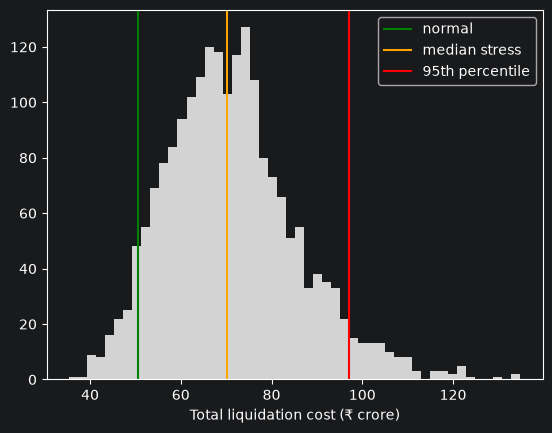

In [13]:
plt.hist(total / cr, bins=50, color="lightgray")
plt.axvline(mc["base_cost"] / cr, color="green", label="normal")
plt.axvline(mc["median"] / cr, color="orange", label="median stress")
plt.axvline(mc["p95"] / cr, color="red", label="95th percentile")
plt.xlabel("Total liquidation cost (₹ crore)")
plt.legend()
plt.show()